# 03 · Report Faithfulness (H3) & Cross-Camera Generalization (H2)

- **H3**: grounding score of LLM incident reports, grounded vs ungrounded
  retrieval conditions (`findings_data/faithfulness.csv`).
- **H2**: view-to-view retrieval recall across UCF-ARG camera views —
  aerial / ground / rooftop (`findings_data/generalization.csv`).

## Part 1 — Faithfulness (H3)

In [1]:
import research_utils as ru

faith = ru.load_findings("faithfulness")
faith

,model,condition,grounding_score,n_supported,n_unsupported
0,vljepa,grounded,0.86,43,7
1,vljepa,ungrounded,0.41,29,42
2,clip,grounded,0.84,42,8
3,clip,ungrounded,0.44,31,39


[research] figure -> h3_grounding_bars.png, h3_grounding_bars.pdf


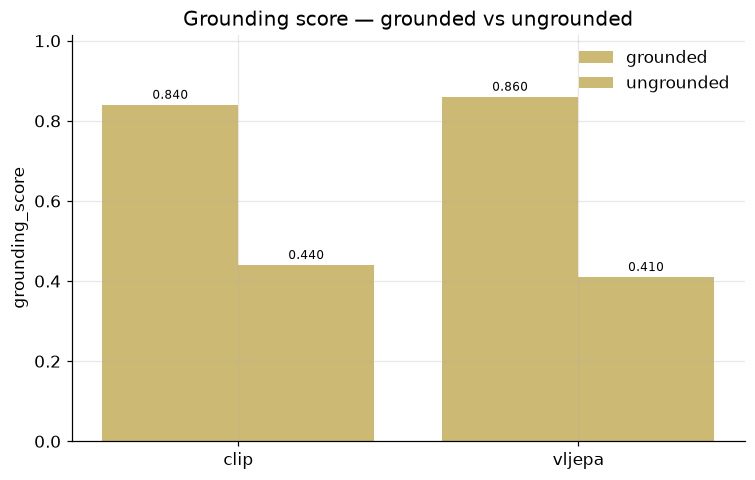

In [2]:
fig, ax = ru.plot_grouped_bars(faith, value="grounding_score",
                              group="model", hue="condition",
                              title="Grounding score — grounded vs ungrounded",
                              save="h3_grounding_bars")

Grounded-vs-ungrounded gap per model (H3 predicts a large positive gap):

In [3]:
pivot = faith.pivot_table(index="model", columns="condition", values="grounding_score")
gap = (pivot["grounded"] - pivot["ungrounded"]).rename("grounding_gap").round(3).to_frame()
gap

,grounding_gap
model,
clip,0.40
vljepa,0.45


In [4]:
ru.export_table(faith, "h3_faithfulness")

[research] table -> h3_faithfulness.csv, h3_faithfulness.tex


[WindowsPath('C:/Users/HPCLAB/Desktop/VLJEPA/capestone/implementation/research/outputs/h3_faithfulness.csv'),
 WindowsPath('C:/Users/HPCLAB/Desktop/VLJEPA/capestone/implementation/research/outputs/h3_faithfulness.tex')]

## Part 2 — Cross-camera generalization (H2)

Diagonal cells = same-view retrieval; off-diagonal = cross-view (the H2 stress test).

In [5]:
gen = ru.load_findings("generalization")
gen.head()

,model,source_view,target_view,recall@1,recall@5
0,vljepa,aerial,aerial,0.551,0.782
1,vljepa,aerial,ground,0.428,0.667
2,vljepa,aerial,rooftop,0.395,0.641
3,vljepa,ground,aerial,0.407,0.652
4,vljepa,ground,ground,0.564,0.798


[research] figure -> h2_generalization_heatmap_r1.png, h2_generalization_heatmap_r1.pdf


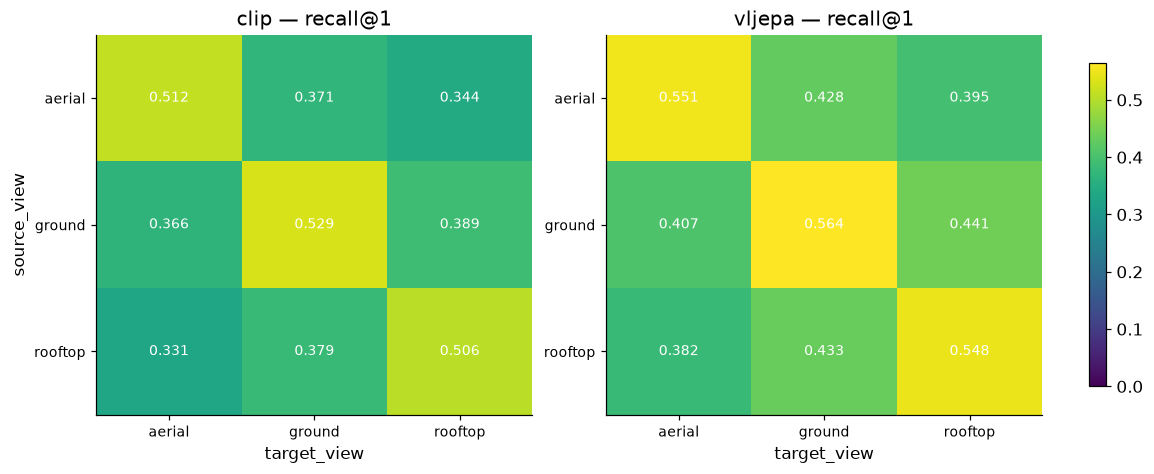

In [6]:
fig, axes = ru.plot_generalization_heatmap(gen, value="recall@1",
                                          save="h2_generalization_heatmap_r1")

[research] figure -> h2_generalization_heatmap_r5.png, h2_generalization_heatmap_r5.pdf


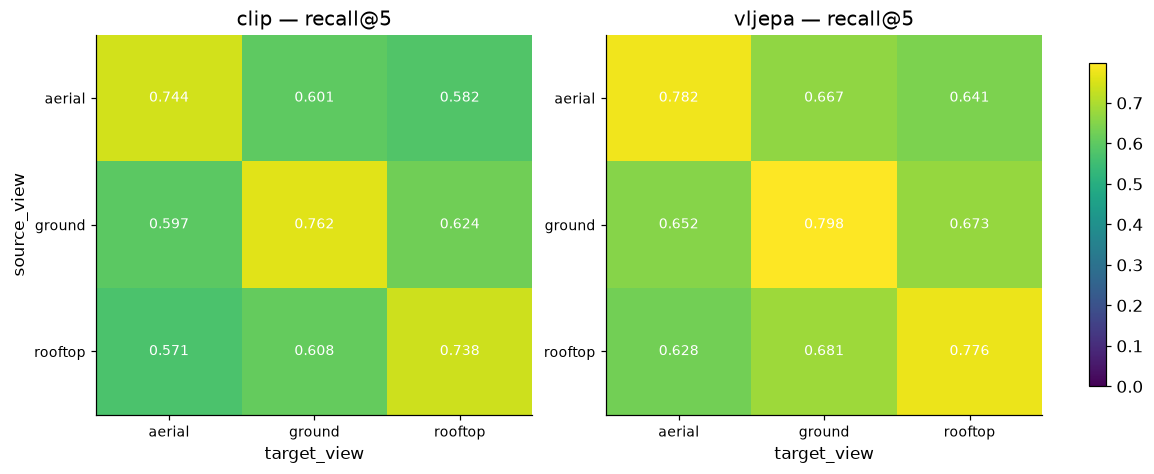

In [7]:
fig, axes = ru.plot_generalization_heatmap(gen, value="recall@5",
                                          save="h2_generalization_heatmap_r5")

Same-view vs cross-view summary (per model):

In [8]:
gen["same_view"] = gen["source_view"] == gen["target_view"]
summary = (gen.groupby(["model", "same_view"])[["recall@1", "recall@5"]]
           .mean().round(3).reset_index())
ru.style_table(summary)

,model,same_view,recall@1,recall@5
0,clip,False,0.363,0.597
1,clip,True,0.516,0.748
2,vljepa,False,0.414,0.657
3,vljepa,True,0.554,0.785


In [9]:
ru.export_table(summary, "h2_same_vs_cross_view")

[research] table -> h2_same_vs_cross_view.csv, h2_same_vs_cross_view.tex


[WindowsPath('C:/Users/HPCLAB/Desktop/VLJEPA/capestone/implementation/research/outputs/h2_same_vs_cross_view.csv'),
 WindowsPath('C:/Users/HPCLAB/Desktop/VLJEPA/capestone/implementation/research/outputs/h2_same_vs_cross_view.tex')]